# Maintenance prédictive et analyse de fiabilité — jeu AI4I 2020

**Objectif.** Montrer, sur un cas industriel complet, la démarche d'un data scientist : collecter et structurer des données (SQL), les contrôler, construire des modèles statistiques (simulation Monte Carlo) et de machine learning (avec une validation adaptée), puis traduire les résultats en **recommandations de décision**.

**Données.** [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset) (UCI n° 601, S. Matzka, 2020, licence CC BY 4.0). Ce jeu est **synthétique** : il imite des données industrielles sans en être. Les conclusions valent donc comme démonstration de méthode, pas comme résultat sur un vrai parc de machines.

**Hypothèses économiques.** Le jeu ne contient aucun coût. Les montants utilisés (panne 2 000 €, changement d'outil 200 €, intervention sur alerte 200 €) sont **illustratifs**, regroupés dans `src/ai4i/config.py`, et une analyse de sensibilité montre ce qui change quand ils varient.

**Plan.** 1. Données, contrôles qualité et SQL · 2. Exploration · 3. Modèles de prédiction et validation · 4. Simulation Monte Carlo et politiques de maintenance · 5. Synthèse et recommandations.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.metrics import average_precision_score

from ai4i import config as C, data, features as F, modeling as M, plots as P, simulation as S

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
RESULTS = {}          # tout ce qui est calculé ici est exporté dans reports/results.json
show = lambda path: display(Image(path))

## 1. Données, contrôles qualité et SQL

On commence par charger le fichier, vérifier sa cohérence et le comparer à la description publiée. Le CSV réel présente plusieurs écarts avec la page UCI : ils sont documentés ici plutôt que supposés absents.

In [2]:
df = data.load_raw()
q = data.quality_report(df)
RESULTS["quality"] = q

# Description publiée (page UCI) vs fichier réel
ecarts = pd.DataFrame([
    ["Répartition des types L / M / H", "50 % / 30 % / 20 %",
     " / ".join(f"{100*q['type_counts'][t]/q['n_rows']:.0f} %" for t in "LMH")],
    ["Pannes par usure (TWF)", "51", q["mode_counts"]["TWF"]],
    ["Pannes aléatoires (RNF)", "5", q["mode_counts"]["RNF"]],
    ["Identifiant", "UID", "UDI"],
    ["« Machine failure » = OU des 5 modes ?", "oui", f"non : {q['mf_without_any_mode']} pannes sans mode, "
                                                   f"{q['mode_without_mf']} modes sans panne"],
    ["RNF = 1 entraîne « Machine failure » = 1 ?", "oui", f"{q['rnf_flagged_with_mf']} cas sur {q['rnf_flagged']}"],
], columns=["Élément", "Description UCI", "Fichier réel"])
display(ecarts)
print("Valeurs manquantes :", q["n_missing"], "| doublons :", q["n_duplicates"])
print("Écarts entre règles documentées et labels (HDF, PWF, OSF) :", q["rule_mismatch"])

,Élément,Description UCI,Fichier réel
0,Répartition des types L / M / H,50 % / 30 % / 20 %,60 % / 30 % / 10 %
1,Pannes par usure (TWF),51,46
2,Pannes aléatoires (RNF),5,19
3,Identifiant,UID,UDI
4,« Machine failure » = OU des 5 modes ?,oui,"non : 9 pannes sans mode, 18 modes sans panne"
5,RNF = 1 entraîne « Machine failure » = 1 ?,oui,1 cas sur 19


Valeurs manquantes : 0 | doublons : 0
Écarts entre règles documentées et labels (HDF, PWF, OSF) : {'HDF': 0, 'PWF': 0, 'OSF': 0}


Les trois règles déterministes **HDF, PWF et OSF** documentées par l'auteur sont reproduites **exactement** (0 écart sur 10 000 lignes). En revanche, le drapeau **RNF** ne déclenche une panne que 1 fois sur 19 : on le traite comme une anomalie de labellisation, pas comme un mode prédictible. Par ailleurs, 9 pannes n'ont aucun mode renseigné (la seule ligne RNF qui provoque une panne porte aussi un TWF) : ces pannes « inexpliquées » représentent 0,09 % des cycles, soit un taux voisin des 0,1 % de défaillance aléatoire annoncé par l'auteur. Le simulateur du §4 utilise ce taux observé.

### Base SQL
Le jeu est chargé dans SQLite et interrogé avec des requêtes (agrégations, fenêtrage `OVER`, `LAG`) rassemblées dans `sql/queries.sql`.

In [3]:
db = data.build_sqlite(df)
sql = data.run_sql_file(db)
for name in ["failure_by_type", "failure_by_wear_bucket", "label_consistency", "tool_life_summary", "failure_rate_per_block"]:
    print(f"--- {name}")
    display(sql[name])
RESULTS["sql_tool_life_summary"] = sql["tool_life_summary"].iloc[0].to_dict()

--- failure_by_type


,type,n_cycles,n_failures,failure_rate_pct
0,H,1003,21,2.09
1,L,6000,235,3.92
2,M,2997,83,2.77


--- failure_by_wear_bucket


,wear_from_min,n_cycles,n_failures,failure_rate_pct,osf,twf,hdf,pwf
0,0,1892,42,2.22,0,0,20,21
1,40,1828,40,2.19,0,0,23,15
2,80,1827,46,2.52,0,0,26,21
3,120,1814,35,1.93,0,0,16,18
4,160,1838,53,2.88,28,1,19,12
5,200,787,119,15.12,67,43,11,8
6,240,14,4,28.57,3,2,0,0


--- label_consistency


,statut,n_lignes
0,cohérent (pas de panne),9643
1,cohérent (panne),330
2,mode renseigné sans panne,18
3,panne sans mode renseigné,9


--- tool_life_summary


,n_complete_tool_lives,mean_end_of_life_wear_min,min_wear,max_wear,n_tool_wear_failures,share_ended_by_failure
0,119,215.7,198,253,46,0.387


--- failure_rate_per_block


,block,n_cycles,n_failures,failure_rate_pct,cumulative_failures
0,0,1000,23,2.3,23
1,1,1000,29,2.9,52
2,2,1000,22,2.2,74
3,3,1000,27,2.7,101
4,4,1000,134,13.4,235
5,5,1000,20,2.0,255
6,6,1000,23,2.3,278
7,7,1000,22,2.2,300
8,8,1000,17,1.7,317
9,9,1000,22,2.2,339


Deux lectures utiles de ces requêtes. **(i)** La requête `failure_by_wear_bucket` montre que le taux de panne est plat (~2 %) jusqu'à 160 min d'usure puis explose au-delà de 200 min. **(ii)** La requête `failure_rate_per_block` fait apparaître un bloc de 1 000 cycles (4 001–5 000) à **13 %** de pannes contre ~2 % ailleurs : il est expliqué plus bas et conditionne toute la stratégie de validation.

La requête `tool_lives` (fenêtrage `LAG`) reconstitue la vie de chaque outil : l'usure repart à zéro au remplacement, et c'est ce mécanisme que reprendra le simulateur.

## 2. Exploration

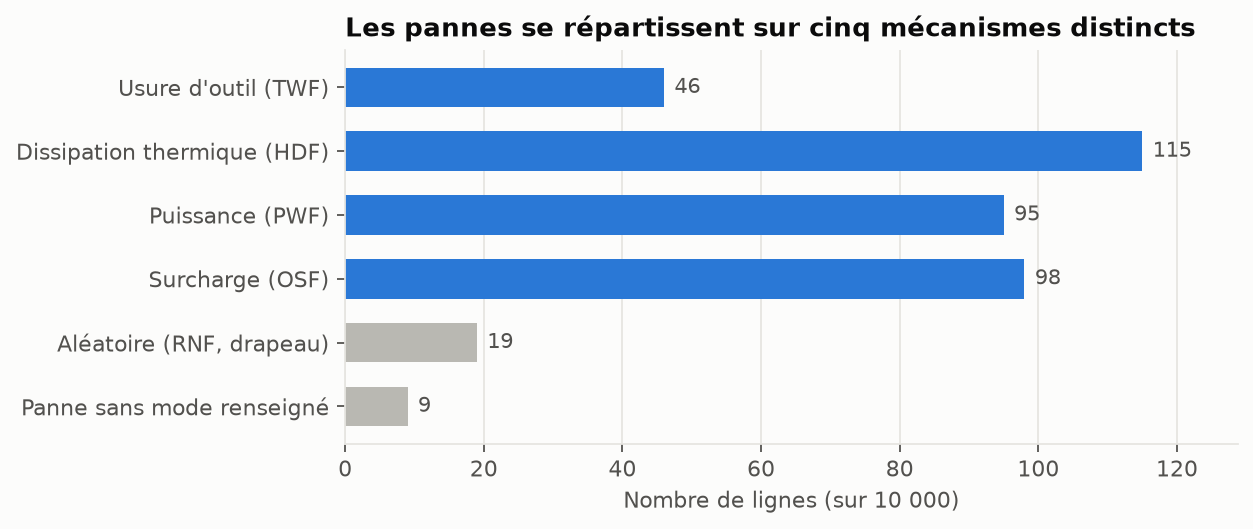

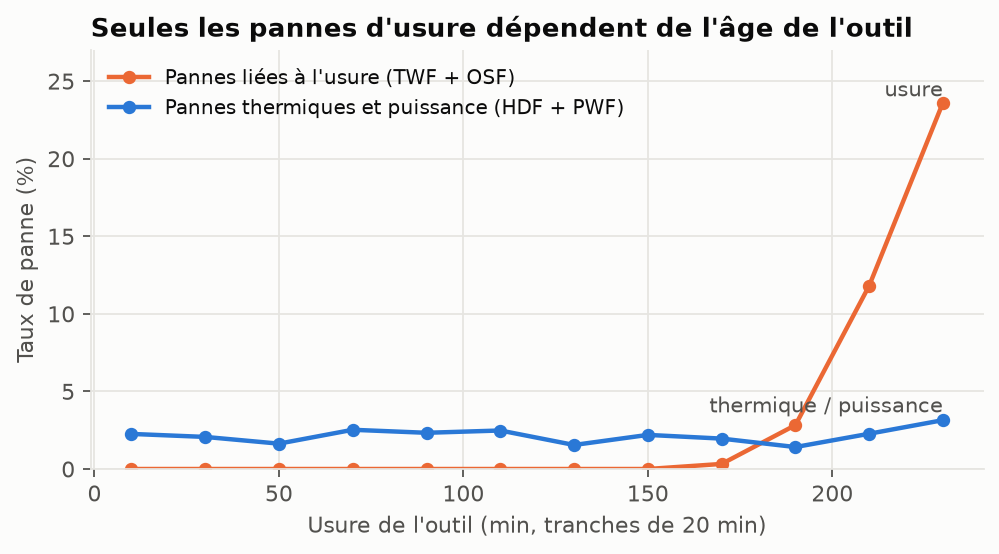

In [4]:
show(P.fig_modes(q["mode_counts"], q["mf_without_any_mode"]))
d = data.add_physics(df)
show(P.fig_wear(d))

Les pannes d'usure (TWF et OSF) n'apparaissent qu'avec l'âge de l'outil, alors que les pannes thermiques et de puissance (HDF, PWF) sont indépendantes de l'usure : **un remplacement préventif ne peut donc agir que sur une partie des pannes**. C'est le fil conducteur de la suite.

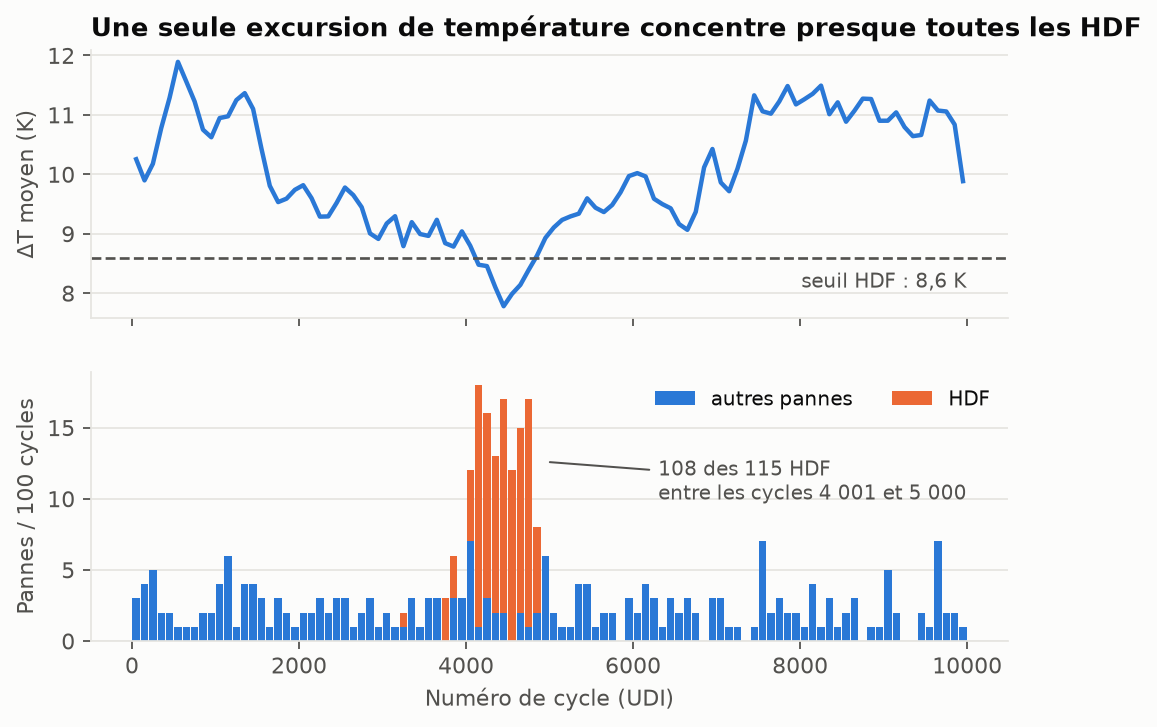

HDF dans l'épisode (cycles 4 001-5 000) : 108 sur 115


In [5]:
show(P.fig_episode(d))
hdf_ep = int(df.loc[(df.udi > 4000) & (df.udi <= 5000), "hdf"].sum())
print(f"HDF dans l'épisode (cycles 4 001-5 000) : {hdf_ep} sur {int(df.hdf.sum())}")
RESULTS["hdf_in_episode"] = hdf_ep

**Les pannes de dissipation thermique forment un seul épisode** : l'écart de température ΔT passe sous 8,6 K pendant environ 1 000 cycles. Les températures sont autocorrélées à 0,999 d'une ligne à l'autre : des lignes voisines se ressemblent, donc une validation croisée **aléatoire** met des voisins du test dans l'entraînement et surestime la performance. Nous validerons donc **par blocs temporels contigus** (avec une zone tampon), ce qui pose la question utile en pratique : *le modèle détecte-t-il un épisode qu'il n'a jamais vu ?*

## 3. Modèles de prédiction

**Variables.** *Brutes* : températures, vitesse, couple, usure, type. *Physiques* : on ajoute l'écart de température ΔT, la puissance (couple × vitesse), le produit usure × couple et la marge de surcharge (usure × couple / seuil du type). Ces variables sont calculables en production et n'utilisent aucun label.

**Validation.** (a) 5 plis aléatoires stratifiés ; (b) 10 blocs contigus de 1 000 cycles, avec 100 cycles écartés de part et d'autre du bloc test. On compare trois familles de modèles (régression logistique, forêt aléatoire, gradient boosting) avec pondération des classes, adaptée au fort déséquilibre (3,4 % de pannes). Métrique principale : **précision moyenne (AP)**, adaptée aux classes déséquilibrées.

cv                              aleatoire  blocs
features model                                  
brut     Gradient Boosting          0.796  0.573
         Random Forest              0.758  0.512
         Régression logistique      0.424  0.347
physique Gradient Boosting          0.899  0.873
         Random Forest              0.890  0.852
         Régression logistique      0.443  0.341

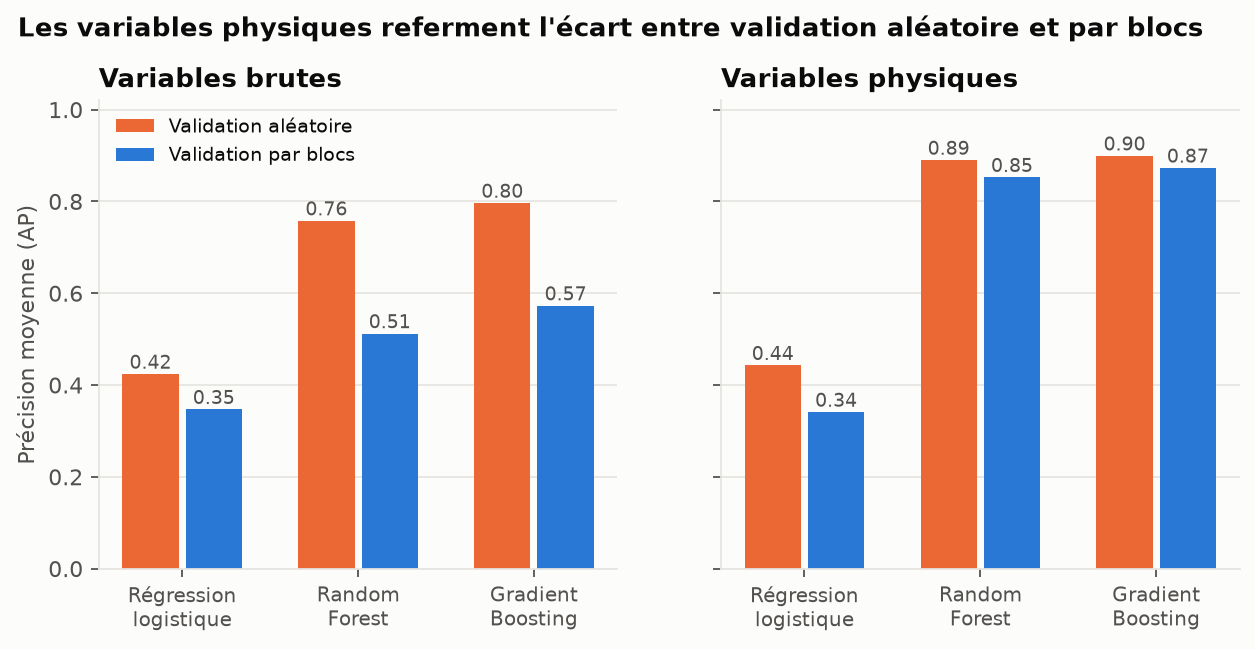

In [6]:
y = df.machine_failure.values; n = len(y)
folds_b = list(M.blocked_folds(n, 10, 100))
fold_id = np.zeros(n, int)
for i, (_, te) in enumerate(folds_b):
    fold_id[te] = i

rows, oof = [], {}
for fs, eng in [("brut", False), ("physique", True)]:
    X = F.make_features(df, eng)
    for name, mdl in M.model_zoo().items():
        for scheme in ["aleatoire", "blocs"]:
            folds = list(M.shuffled_folds(y, 5)) if scheme == "aleatoire" else folds_b
            p, _ = M.oof_predict(mdl, X, y, folds)
            oof[(fs, name, scheme)] = p
            rows.append(dict(features=fs, model=name, cv=scheme, **M.metrics_row(y, p)))
cv = pd.DataFrame(rows)
RESULTS["cv_table"] = cv.to_dict("records")
display(cv.pivot_table(index=["features", "model"], columns="cv", values="ap").round(3))
show(P.fig_cv_gap(cv))

Avec les variables **brutes**, la performance s'effondre dès qu'on valide par blocs : le modèle n'avait pas appris la physique, il reconnaissait des périodes. Avec les variables **physiques**, l'écart se réduit nettement. La régression logistique reste faible, ce qui est normal : les pannes sont déclenchées par des seuils et des produits de variables, des relations non linéaires.

### Un modèle par mode de panne

Plutôt qu'un modèle unique pour « panne », on entraîne **un modèle par mécanisme** (TWF, HDF, PWF, OSF) et on les combine par un « OU ». Test le plus exigeant : on retire de l'entraînement **tout l'intervalle 3 900–5 100** (l'épisode HDF et son voisinage) et on prédit l'épisode, qu'on n'a donc jamais vu, à partir des 7 seuls événements HDF isolés restants.

In [7]:
gb = M.model_zoo()["Gradient Boosting"]
Xe, Xr = F.make_features(df, True), F.make_features(df, False)

# Test de l'épisode inconnu (HDF)
hdf = df.hdf.values
tr = np.r_[0:3900, 5100:n]; te = np.arange(4000, 5000)
ep = {"hdf_train": int(hdf[tr].sum()), "hdf_episode": int(hdf[te].sum())}
for lab, X in [("physique", Xe), ("brut", Xr)]:
    from sklearn.base import clone
    m = clone(gb).fit(X.iloc[tr], hdf[tr]); pr = m.predict_proba(X.iloc[te])[:, 1] >= 0.5
    ep[lab] = dict(detectes=int((pr & (hdf[te] == 1)).sum()), manques=int((~pr & (hdf[te] == 1)).sum()),
                   fausses_alertes=int((pr & (hdf[te] == 0)).sum()))
RESULTS["episode_test"] = ep
print(f"Entraînement : {ep['hdf_train']} événements HDF isolés | épisode à prédire : {ep['hdf_episode']} HDF")
display(pd.DataFrame({k: ep[k] for k in ["physique", "brut"]}).T.rename(columns={"detectes": "détectées", "manques": "manquées"}))

# Modèles par mode (validation par blocs)
modes_p = M.mode_oof_predictions(df, Xe, folds_b, gb)
rows = []
for t in M.MODE_TARGETS:
    yt = df[t].values; pm = modes_p[t]
    r = M.prf(yt, pm >= 0.5)
    rows.append(dict(mode=t.upper(), evenements=int(yt.sum()), ap=average_precision_score(yt, pm),
                     prevalence=yt.mean(), precision=r["precision"], rappel=r["recall"]))
mode_tab = pd.DataFrame(rows); RESULTS["mode_table"] = mode_tab.to_dict("records")
display(mode_tab.round(3))

Entraînement : 7 événements HDF isolés | épisode à prédire : 108 HDF


,détectées,manquées,fausses_alertes
physique,108,0,0
brut,19,89,1


,mode,evenements,ap,prevalence,precision,rappel
0,TWF,46,0.067,0.005,0.059,0.065
1,HDF,115,1.000,0.012,1.000,1.000
2,PWF,95,0.990,0.010,1.000,0.979
3,OSF,98,0.999,0.010,0.990,0.990


Avec les variables physiques, le modèle HDF retrouve **l'intégralité de l'épisode inconnu sans fausse alerte**, là où les variables brutes n'en détectent qu'une petite part. HDF, PWF et OSF sont quasi parfaitement prédits. En revanche **TWF reste imprévisible** : sa précision moyenne est proche de sa prévalence. C'est cohérent avec le mécanisme documenté (fin de vie de l'outil tirée au hasard entre 200 et 240 min) : l'usure indique *quand* le risque existe, pas *quel* outil cassera.

### Décision : combien coûte chaque stratégie ?

Un score de classement ne dit pas ce qu'on économise. On compare des stratégies sur le **coût total** (alerte = 200 €, panne manquée = 2 000 €, hypothèses illustratives). Le seuil de décision de chaque modèle est choisi **hors-échantillon** (sur les autres blocs) avant d'être appliqué au bloc évalué. Références : « sans modèle » (toutes les pannes subies) et les **règles exactes** (seuils connus, sans apprentissage), qui donnent le plafond atteignable.

,name,ap,precision,recall,f1,tp,fp,fn,cost,IC95 précision,IC95 rappel
0,"Modèle unique, variables brutes",0.573,0.232,0.673,0.345,228.0,754.0,111.0,418400.0,[0.19 ; 0.29],[0.51 ; 0.92]
1,"Modèle unique, variables physiques",0.873,0.659,0.794,0.720,269.0,139.0,70.0,221600.0,[0.56 ; 0.74],[0.72 ; 0.85]
2,OU des modèles HDF + PWF + OSF,0.859,0.997,0.841,0.912,285.0,1.0,54.0,165200.0,[0.99 ; 1.00],[0.76 ; 0.89]
3,OU des 4 modèles (avec TWF),0.911,0.932,0.844,0.885,286.0,21.0,53.0,167400.0,[0.87 ; 0.97],[0.76 ; 0.89]
4,Règles exactes (plafond),NaN,1.000,0.847,0.917,287.0,0.0,52.0,161400.0,[1.00 ; 1.00],[0.77 ; 0.90]
5,Sans modèle,NaN,NaN,NaN,NaN,NaN,NaN,NaN,678000.0,,


IC95 : bootstrap par blocs de 500 cycles (respecte l'autocorrélation).


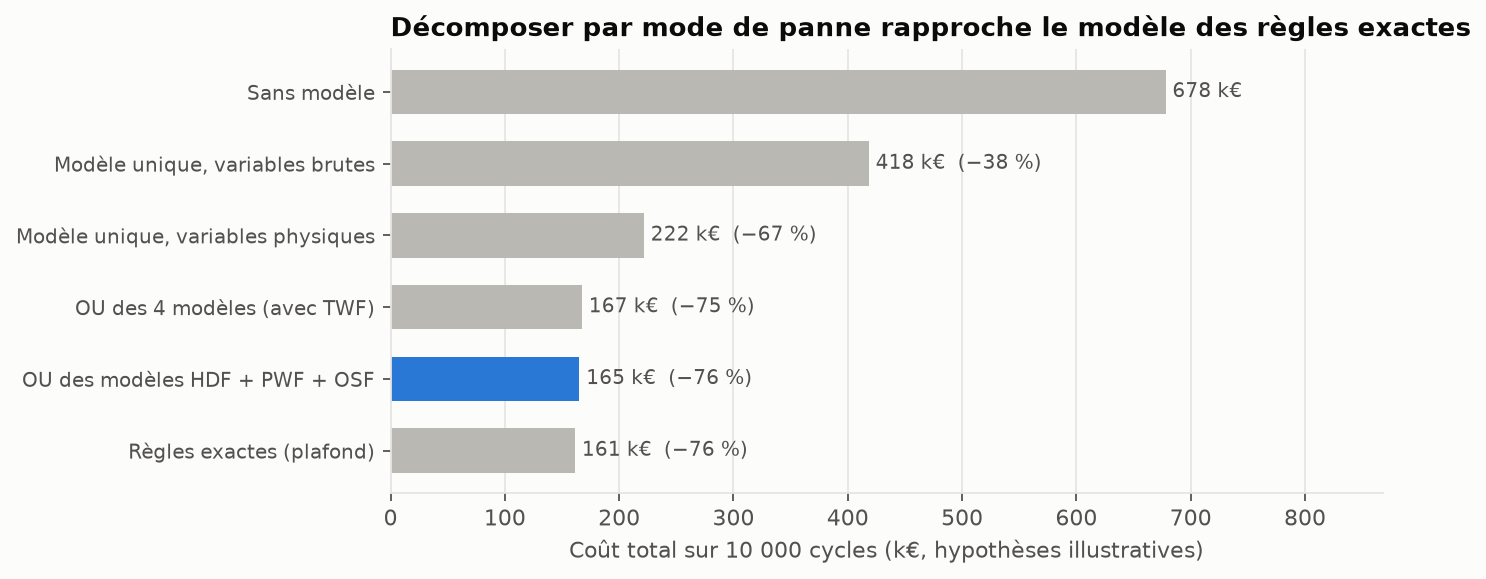

In [8]:
strategies = []
strategies.append(M.strategy_summary("Modèle unique, variables brutes", y, oof[("brut", "Gradient Boosting", "blocs")], fold_id, is_proba=True, n_boot=500))
strategies.append(M.strategy_summary("Modèle unique, variables physiques", y, oof[("physique", "Gradient Boosting", "blocs")], fold_id, is_proba=True, n_boot=500))
p_or3 = M.combine_or(modes_p, ["hdf", "pwf", "osf"])
p_or4 = M.combine_or(modes_p, ["twf", "hdf", "pwf", "osf"])
strategies.append(M.strategy_summary("OU des modèles HDF + PWF + OSF", y, p_or3, fold_id, is_proba=True, n_boot=500))
strategies.append(M.strategy_summary("OU des 4 modèles (avec TWF)", y, p_or4, fold_id, is_proba=True, n_boot=500))
rule_pred = data.rule_flags(df).sum(axis=1).values > 0
strategies.append(M.strategy_summary("Règles exactes (plafond)", y, rule_pred, fold_id, is_proba=False, n_boot=500))
baseline_cost = float(y.sum() * C.COSTS["failure"])
strategies.append(dict(name="Sans modèle", cost=baseline_cost))

tab = pd.DataFrame([{k: s.get(k) for k in ["name", "ap", "precision", "recall", "f1", "tp", "fp", "fn", "cost"]} for s in strategies])
ci = lambda v: "" if v is None else f"[{v[0]:.2f} ; {v[1]:.2f}]"
tab["IC95 précision"] = [ci(s.get("precision_ci")) for s in strategies]
tab["IC95 rappel"] = [ci(s.get("recall_ci")) for s in strategies]
display(tab.round(3))
print("IC95 : bootstrap par blocs de 500 cycles (respecte l'autocorrélation).")
RESULTS["strategies"] = strategies; RESULTS["baseline_cost"] = baseline_cost
best_name = "OU des modèles HDF + PWF + OSF"
show(P.fig_decision(strategies, baseline_cost, highlight=best_name))

Le **modèle binaire unique** laisse beaucoup de valeur sur la table (précision et rappel nettement plus faibles) alors que la **combinaison de modèles par mode** s'approche du plafond fixé par les règles exactes, en les *apprenant* à partir des données. Ajouter le modèle TWF n'améliore pas le coût : sa seule contribution est du bruit. Le rappel plafonne autour de 85 % : les ~15 % restants (TWF, pannes inexpliquées) sont **imprévisibles avec ces capteurs**, et aucun modèle ne les rattrapera.

### Ce que les modèles ont appris

Importance par permutation mesurée sur chaque bloc test : baisse d'AP quand on mélange une variable. Si la physique est bien apprise, chaque mode doit s'appuyer sur sa grandeur causale.

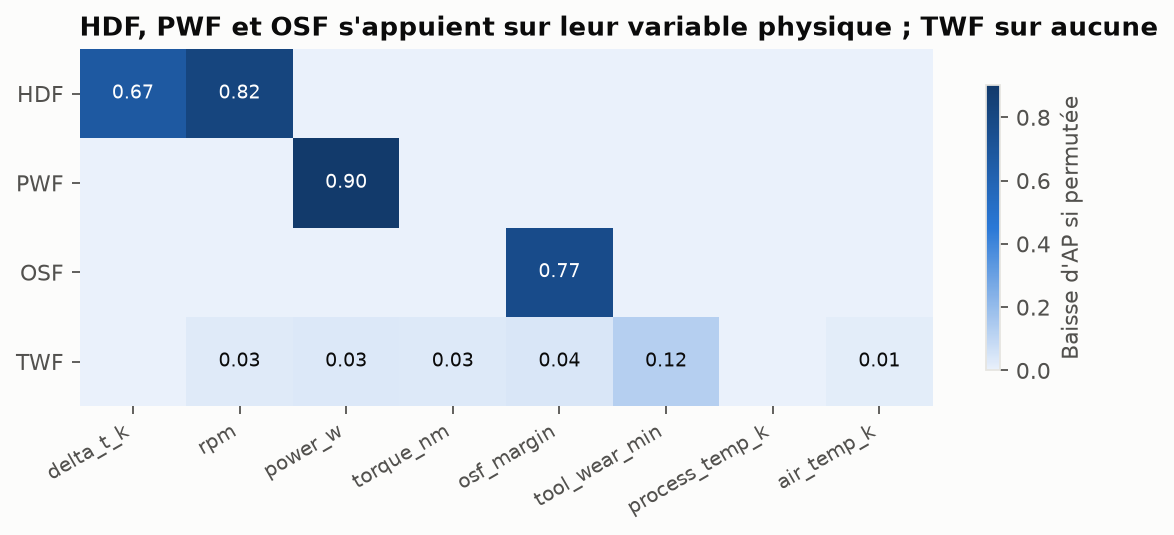

In [9]:
imps = {t.upper(): M.per_mode_importance(gb, Xe, df[t].values, folds_b) for t in ["hdf", "pwf", "osf", "twf"]}
imp = pd.DataFrame(imps).T[["delta_t_k", "rpm", "power_w", "torque_nm", "osf_margin", "tool_wear_min", "process_temp_k", "air_temp_k"]]
RESULTS["importance"] = imp.round(4).to_dict("index")
show(P.fig_importance(imp))

Lecture : **HDF** s'appuie sur ΔT et la vitesse, **PWF** sur la puissance, **OSF** sur la marge de surcharge (usure × couple) ; **TWF** n'a pas de variable dominante. Les modèles retrouvent les mécanismes physiques documentés, ce qui est un argument de confiance pour les équipes métier (le modèle n'exploite pas un artefact).

## 4. Simulation Monte Carlo

### Un générateur ajusté sur les données
On simule le process cycle par cycle à partir de la mécanique observée dans les données :

- **Type de produit** tiré selon les fréquences observées (60/30/10 %) ; l'usure augmente de **2, 3 ou 5 min** selon le type (relation retrouvée *exactement* dans les données) et repart à 0 au remplacement de l'outil.
- **Fin de vie de l'outil** tirée dans la distribution empirique des 119 fins de vie observées ; à ce moment, panne par usure (TWF) avec la probabilité observée.
- **Couple et puissance** : loi normale bivariée (corrélation estimée), vitesse = puissance / couple. **ΔT** : processus AR(1) (reproduit les épisodes de plusieurs centaines de cycles).
- **HDF, PWF, OSF** : règles déterministes documentées ; **pannes inexpliquées** : tirage de Bernoulli (0,1 %).

*Validation* : on simule 2 000 fenêtres indépendantes de 10 000 cycles (la taille du jeu) et on compare au compte observé. **TWF** et les pannes inexpliquées sont *calibrées* sur les données ; HDF, PWF, OSF, la distribution de l'usure et celle de la vitesse sont de vraies vérifications.

{'type_probs': {'L': 0.6, 'M': 0.2997, 'H': 0.1003}, 'wear_inc': {'L': 2, 'M': 3, 'H': 5}, 'torque_mu': 39.9869, 'torque_sd': 9.9689, 'power_mu': 6279.745, 'power_sd': 1067.4183, 'rho_tp': 0.9788, 'dT_mu': 10.0006, 'dT_sd': 1.0011, 'dT_phi': 0.9975, 'p_twf': 0.3866, 'p_unexplained': 0.0009}
Fins de vie observées : 119 | moyenne 215.7 min 198 max 253


,mode,observé (10 000 cycles),simulé moyen,simulé IC95 moyenne,simulé P2.5,simulé P97.5,rang percentile de l'observé
0,HDF,115,109.8,(106.6 ; 113.0),10.0,288.0,61.3
1,PWF,95,100.2,(99.8 ; 100.7),82.0,120.0,33.4
2,OSF,98,101.8,(101.3 ; 102.3),81.0,125.0,40.8
3,TWF,46,45.9,(45.6 ; 46.1),35.0,56.0,56.0
4,UNEXPLAINED,9,9.1,(9.0 ; 9.2),4.0,16.0,57.2
5,ANY_FAILURE,339,339.4,(336.4 ; 342.4),242.0,505.0,58.2


Écart max des fonctions de répartition — usure : 0.0034 | vitesse : 0.0124
Taux de remplacement d'outil — simulé : 1.186 % | observé : 1.190 %


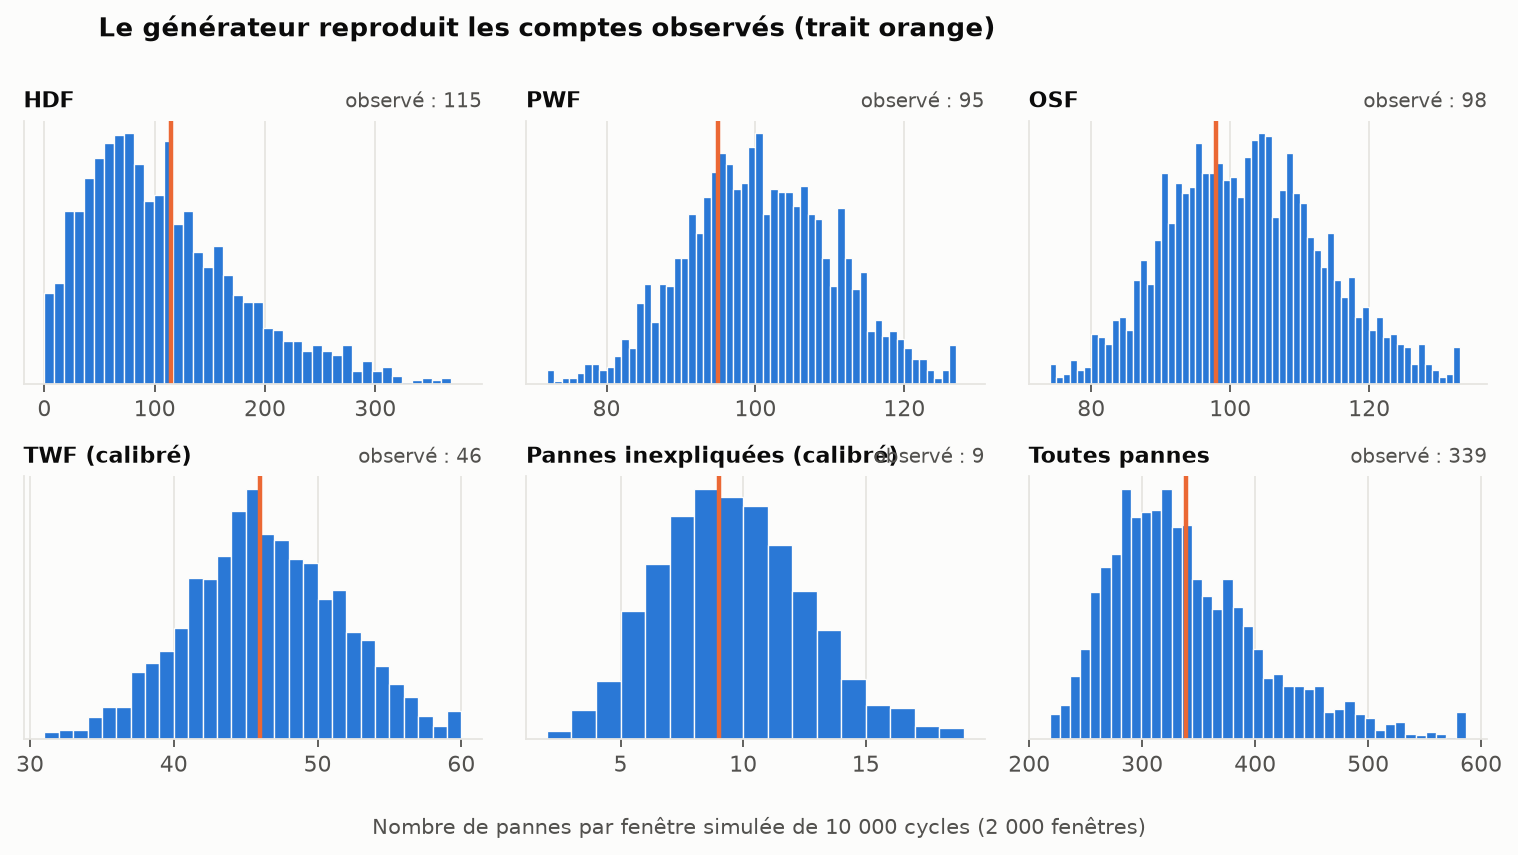

In [10]:
gp = S.fit_generator(df)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in gp.__dict__.items() if k != "eol_wear"})
print("Fins de vie observées :", len(gp.eol_wear), "| moyenne", round(gp.eol_wear.mean(), 1), "min", gp.eol_wear.min(), "max", gp.eol_wear.max())
val = S.validate_generator(df, gp, n_windows=2000)
vt = val["table"].copy()
vt["simulé IC95 moyenne"] = vt["simulé IC95 moyenne"].apply(lambda t: f"({t[0]:.1f} ; {t[1]:.1f})")
display(vt.round(1))
print(f"Écart max des fonctions de répartition — usure : {val['ks_wear']:.4f} | vitesse : {val['ks_rpm']:.4f}")
print(f"Taux de remplacement d'outil — simulé : {100*val['replacement_rate_sim']:.3f} % | observé : {100*val['replacement_rate_obs']:.3f} %")
RESULTS["mc_validation"] = {"table": val["table"].astype(object).to_dict("records"), "ks_wear": val["ks_wear"],
                            "ks_rpm": val["ks_rpm"], "replacement_rate_sim": val["replacement_rate_sim"],
                            "replacement_rate_obs": val["replacement_rate_obs"]}
RESULTS["generator"] = {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in gp.__dict__.items()}
show(P.fig_mc_validation(val))

Le nombre moyen de pannes simulé sur 10 000 cycles est très proche du nombre observé, et les comptes de HDF, PWF et OSF tombent dans la zone plausible. Le comportement de HDF est instructif : sa distribution simulée est très étalée (de quelques unités à plus de 250 par fenêtre) parce que ces pannes arrivent par épisodes ; **l'observation unique du jeu est donc très peu informative sur le taux de HDF « à long terme »**, ce que le simulateur quantifie.

### Politiques de maintenance préventive
On compare des règles « remplacer l'outil dès que l'usure atteint W minutes » à la situation actuelle (aucun remplacement préventif ; l'outil va jusqu'à sa fin de vie). Les politiques sont simulées avec les **mêmes aléas** (nombres aléatoires communs), ce qui rend les écarts de coût très précis. Un contrôle intégré : le taux de remplacement simulé doit suivre la théorie du renouvellement (voir tests).

Hypothèses : coût d'une panne 2 000 €, d'un changement d'outil 200 € ; une panne autre que l'usure n'impose pas de changer l'outil ; HDF et PWF ne dépendent pas de l'usure.

,"W (min, NaN = sans préventif)",pannes_par_1000,remplacements_par_1000,dont_preventifs_par_1000,cout_par_1000,cout_ic95,gain_vs_base,gain_ic95
0,NaN,34.0,11.9,0.0,70468.9,644.4,-0.0,0.0
1,240.0,33.7,11.9,0.3,69867.8,643.6,601.1,66.6
2,220.0,31.3,12.0,3.2,65069.3,644.2,5399.6,146.6
3,200.0,24.3,12.8,12.1,51235.7,655.2,19233.2,155.2
4,190.0,22.6,13.4,13.4,47900.4,659.6,22568.5,145.7
5,180.0,21.9,14.2,14.2,46577.3,662.4,23891.6,144.1
6,170.0,21.6,15.0,15.0,46237.3,663.5,24231.6,143.5
7,160.0,21.6,15.9,15.9,46337.2,663.7,24131.7,143.4
8,150.0,21.6,16.9,16.9,46546.7,663.6,23922.2,143.4
9,140.0,21.6,18.1,18.1,46779.6,663.7,23689.3,143.4


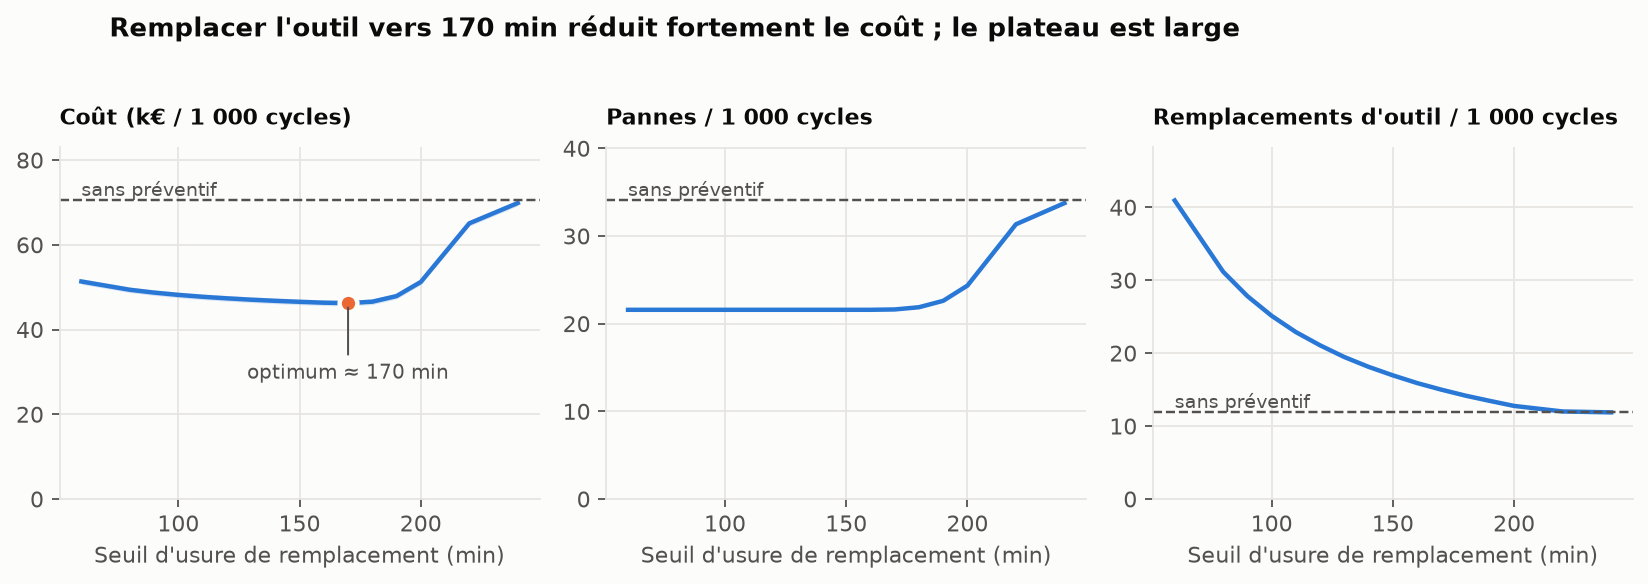

Optimum de la grille : W = 170 min | coût 46,237 € / 1 000 cycles contre 70,469 € sans préventif (34 % d'économie)
Plateau (coût à moins de 1 % de l'optimum) : W entre 150 et 180 min


In [11]:
runs = S.run_policies(gp, n_machines=20000, n_steps=800, burn_in=300, seed=7)
pol = S.policy_table(runs)
RESULTS["policy_table"] = pol.replace({np.inf: "inf"}).to_dict("records")
disp = pol.copy()
disp["seuil_preventif_min"] = disp["seuil_preventif_min"].replace(np.inf, np.nan)
display(disp.round(1).rename(columns={"seuil_preventif_min": "W (min, NaN = sans préventif)"}))
show(P.fig_policy(pol))
fin = pol[np.isfinite(pol.seuil_preventif_min)]
wstar = fin.loc[fin.cout_par_1000.idxmin()]
base = pol[~np.isfinite(pol.seuil_preventif_min)].iloc[0]
plateau = fin[fin.cout_par_1000 <= 1.01 * wstar.cout_par_1000].seuil_preventif_min
print(f"Optimum de la grille : W = {int(wstar.seuil_preventif_min)} min | coût {wstar.cout_par_1000:,.0f} € / 1 000 cycles "
      f"contre {base.cout_par_1000:,.0f} € sans préventif ({100*(1-wstar.cout_par_1000/base.cout_par_1000):.0f} % d'économie)")
print(f"Plateau (coût à moins de 1 % de l'optimum) : W entre {int(plateau.min())} et {int(plateau.max())} min")
RESULTS["policy_plateau"] = [float(plateau.min()), float(plateau.max())]

Les pannes d'usure (TWF, OSF) disparaissent quand on remplace tôt, mais les pannes **HDF et PWF restent entières** : elles forment le plancher de la courbe des pannes et ne se traitent pas par la maintenance de l'outil. Une fois ce plancher atteint, descendre encore le seuil n'évite plus aucune panne et ajoute seulement des changements d'outil, d'où la remontée du coût. La courbe de coût est **très plate autour de l'optimum** (voir le plateau calculé ci-dessus) : recommander une valeur unique à la minute près serait exagérer la précision.

,coût panne / coût changement,W optimal (min),économie (%)
0,2.0,180.0,27.6
1,3.0,180.0,30.0
2,5.0,170.0,32.4
3,7.5,170.0,33.7
4,10.0,170.0,34.4
5,15.0,170.0,35.1
6,20.0,170.0,35.4
7,30.0,160.0,35.8
8,50.0,160.0,36.1
9,100.0,160.0,36.4


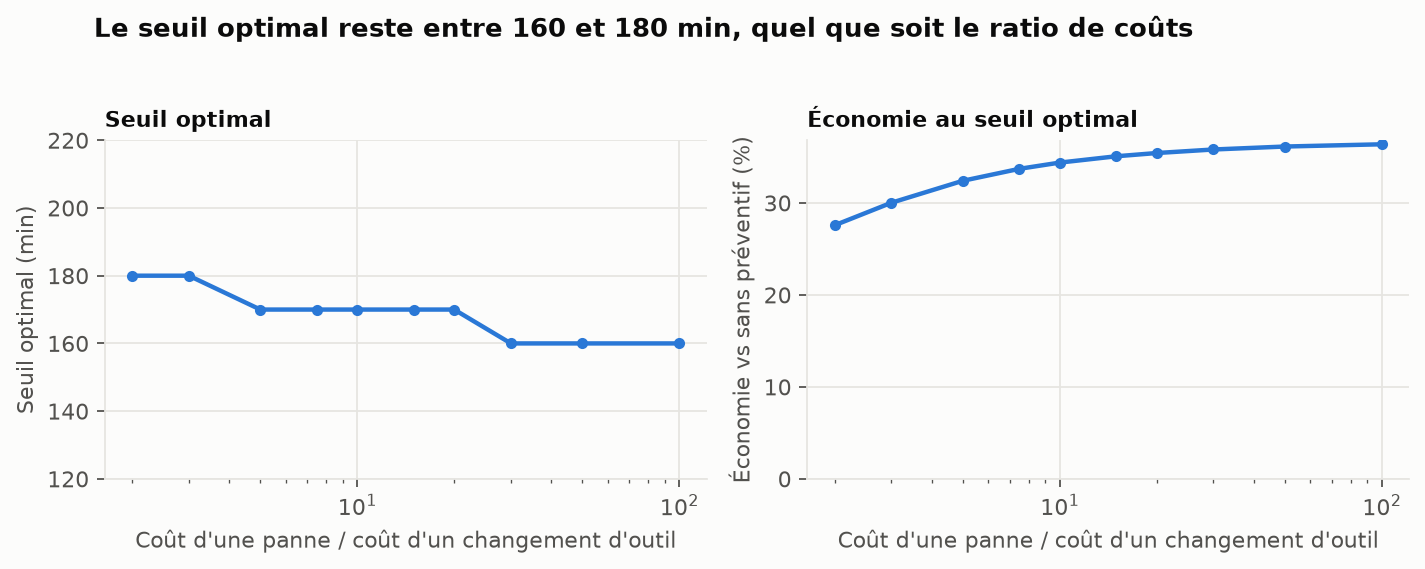

In [12]:
sens = S.cost_sensitivity(runs)
RESULTS["sensitivity"] = sens.to_dict("records")
display(sens.round(1).rename(columns={"ratio": "coût panne / coût changement", "w_star": "W optimal (min)", "saving_pct": "économie (%)"}))
show(P.fig_sensitivity(sens))

Que la panne coûte 2 ou 100 fois un changement d'outil, **le seuil optimal reste entre 160 et 180 min** et l'économie entre ~28 % et ~36 % (valeurs de la table ci-dessus) : la recommandation est robuste aux hypothèses de coût, même si le montant absolu ne l'est pas.

## 5. Synthèse et recommandations

In [13]:
s = {x["name"]: x for x in strategies}
rec, oracle, single = s[best_name], s["Règles exactes (plafond)"], s["Modèle unique, variables physiques"]
ep_ = RESULTS["episode_test"]
txt = f"""
**Ce que montre l'étude**

1. **Contrôle des données.** Le fichier réel s'écarte de sa description (répartition des types, nombre de TWF et de RNF, labels incohérents). Les règles HDF, PWF et OSF sont reproduites sans aucun écart ; le drapeau RNF est inutilisable ({q['rnf_flagged_with_mf']} cas sur {q['rnf_flagged']}).
2. **Validation.** Une validation croisée aléatoire est trompeuse ici (températures autocorrélées à 0,999, un seul épisode HDF). La validation par blocs temporels est la seule qui mesure la généralisation à un épisode inconnu.
3. **Variables physiques.** Elles permettent de détecter {ep_['physique']['detectes']} des {ep_['hdf_episode']} HDF d'un épisode jamais vu ({ep_['physique']['fausses_alertes']} fausse alerte), contre {ep_['brut']['detectes']} avec les variables brutes.
4. **Décomposer par mode.** La combinaison de modèles HDF + PWF + OSF atteint une précision de {rec['precision']:.3f} et un rappel de {rec['recall']:.3f}, pour un coût de {rec['cost']/1000:,.0f} k€ ; le modèle binaire unique donne {single['cost']/1000:,.0f} k€, les règles exactes {oracle['cost']/1000:,.0f} k€ et l'absence de modèle {baseline_cost/1000:,.0f} k€ (hypothèses illustratives).
5. **Limite structurelle.** Les pannes TWF et inexpliquées (~15 % des pannes) sont imprévisibles avec ces capteurs.
6. **Maintenance préventive.** Remplacer l'outil vers {int(wstar.seuil_preventif_min)} min (coût à moins de 1 % de l'optimum entre {int(plateau.min())} et {int(plateau.max())} min) réduit le coût simulé de {100*(1-wstar.cout_par_1000/base.cout_par_1000):.0f} % ; le seuil optimal reste entre {int(sens.w_star.min())} et {int(sens.w_star.max())} min quand le ratio de coûts varie de {sens.ratio.min():g} à {sens.ratio.max():g}. Le reliquat de pannes (HDF, PWF) relève de la surveillance en ligne, donc du modèle prédictif.

**Recommandations** : (a) mettre en place le remplacement préventif de l'outil vers {int(wstar.seuil_preventif_min)} min (plage {int(plateau.min())}–{int(plateau.max())} min à ajuster avec les vrais coûts) ; (b) déployer l'alerte par modèles par mode sur HDF/PWF/OSF pour le reliquat, en fixant le seuil d'alerte avec les vrais coûts ; (c) ne pas investir dans la prédiction de TWF avec ces seules mesures.
"""
display(Markdown(txt))


**Ce que montre l'étude**

1. **Contrôle des données.** Le fichier réel s'écarte de sa description (répartition des types, nombre de TWF et de RNF, labels incohérents). Les règles HDF, PWF et OSF sont reproduites sans aucun écart ; le drapeau RNF est inutilisable (1 cas sur 19).
2. **Validation.** Une validation croisée aléatoire est trompeuse ici (températures autocorrélées à 0,999, un seul épisode HDF). La validation par blocs temporels est la seule qui mesure la généralisation à un épisode inconnu.
3. **Variables physiques.** Elles permettent de détecter 108 des 108 HDF d'un épisode jamais vu (0 fausse alerte), contre 19 avec les variables brutes.
4. **Décomposer par mode.** La combinaison de modèles HDF + PWF + OSF atteint une précision de 0.997 et un rappel de 0.841, pour un coût de 165 k€ ; le modèle binaire unique donne 222 k€, les règles exactes 161 k€ et l'absence de modèle 678 k€ (hypothèses illustratives).
5. **Limite structurelle.** Les pannes TWF et inexpliquées (~15 % des pannes) sont imprévisibles avec ces capteurs.
6. **Maintenance préventive.** Remplacer l'outil vers 170 min (coût à moins de 1 % de l'optimum entre 150 et 180 min) réduit le coût simulé de 34 % ; le seuil optimal reste entre 160 et 180 min quand le ratio de coûts varie de 2 à 100. Le reliquat de pannes (HDF, PWF) relève de la surveillance en ligne, donc du modèle prédictif.

**Recommandations** : (a) mettre en place le remplacement préventif de l'outil vers 170 min (plage 150–180 min à ajuster avec les vrais coûts) ; (b) déployer l'alerte par modèles par mode sur HDF/PWF/OSF pour le reliquat, en fixant le seuil d'alerte avec les vrais coûts ; (c) ne pas investir dans la prédiction de TWF avec ces seules mesures.


### Limites et suites

- **Données synthétiques** : les ordres de grandeur et la facilité apparente de prédiction (HDF/PWF/OSF obéissent à des règles) ne se transposent pas à un vrai parc. L'intérêt est la méthode.
- **Étiquettes de mode** : le modèle « par mode » suppose de disposer d'un label par mécanisme, ce qui exige en pratique une analyse de causes racines.
- **Coûts illustratifs** : à remplacer par ceux du client ; la sensibilité montre quoi attendre.
- **Simulateur** : cycles supposés indépendants hors usure et ΔT ; un remplacement d'outil ne modifie pas HDF/PWF ; la fin de vie de l'outil est tirée dans les 119 observations (incertitude d'échantillonnage non propagée).
- **Suites naturelles** : combiner explicitement politique préventive et alertes dans la simulation ; intervalles d'incertitude sur les paramètres du générateur (bootstrap) ; modèles de survie pour la fin de vie de l'outil.

In [14]:
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, float): return None if not np.isfinite(o) else o
    if isinstance(o, np.ndarray): return _clean(o.tolist())
    return o
RESULTS["headline"] = {
    "recommended_strategy": best_name, "recommended_cost": rec["cost"], "baseline_cost": baseline_cost,
    "oracle_cost": oracle["cost"], "single_model_cost": single["cost"],
    "w_star": float(wstar.seuil_preventif_min), "policy_saving_pct": float(100 * (1 - wstar.cout_par_1000 / base.cout_par_1000)),
}
C.RESULTS_JSON.parent.mkdir(parents=True, exist_ok=True)
C.RESULTS_JSON.write_text(json.dumps(_clean(RESULTS), ensure_ascii=False, indent=1), encoding="utf-8")
print("Résultats exportés :", C.RESULTS_JSON.relative_to(ROOT))

Résultats exportés : reports\results.json
